# Correlation Analysis between PC Scores and Environmental Parameters

## Method Explanation
In this notebook, we analyze the spatiotemporal relationships between Dissolved Oxygen (represented by PCA patterns) and environmental factors across all stations.
Specifically:
1. **Data Loading**: We rely on pre-calculated per-station Pearson correlations (`pca_env_corr_pc1.csv` and `pca_env_corr_pc2.csv`), outputted by the pipeline step `pca_env_corr`. These files store the correlation ($r$) between PCA temporal scores (PC1, PC2) and environmental time series at each station.
2. **Correlation Boxplots**: We use boxplots to visualize the distribution of per-station correlation coefficients for all evaluated environmental parameters. This helps identify which factors consistently exhibit strong positive or negative relationships with the localized PCA scores across the region.
3. **DO Loadings vs. Parameter Correlation**: We utilize the spatial PCA loadings (which quantify the extent of DO variation patterned at each station) and map them directly against the correlation strength for particular parameters (e.g., Spring Chlorophyll-a). This scatterplot, colored by water mass (division), reveals regional structuring where the environmental driver and DO pattern co-occur.

## Result Interpretation
* A median correlation value deviating significantly from 0 in the boxplots indicates a dominant positive or negative driver for the specified Principal Component pattern.
* In the scatterplots, distinct clustering of water masses reveals region-specific environmental controls. Stations with strong parameter correlations and high PCA loadings indicate that the specific factor strongly dictates DO at those locations.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

# Configure plots
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

# Setup paths (Assuming execution from within SIS_Analysis/notebooks)
sys.path.append(str(Path.cwd().parent / 'scripts'))
from paths import ProjectPaths

season = 'Summer'
layer = 'bottom'
subset_dir = ProjectPaths.get_subset_dir(season, layer)


In [3]:
# Load pre-calculated pipeline outputs
print("Loading data...")
corr_df_pc1 = pd.read_csv(subset_dir / 'pca_env_corr_pc1.csv', dtype={'zettaicode': str}).set_index('zettaicode')
corr_df_pc2 = pd.read_csv(subset_dir / 'pca_env_corr_pc2.csv', dtype={'zettaicode': str}).set_index('zettaicode')
pca_loadings = pd.read_csv(subset_dir / 'pca_loadings.csv', dtype={'zettaicode': str}).set_index('zettaicode')

# Load merged data for water mass division mapping
merged_df = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
merged_df['zettaicode'] = merged_df['zettaicode'].astype(str).str.zfill(8)
divisions = merged_df[['zettaicode', 'division']].drop_duplicates('zettaicode').set_index('zettaicode')

print("Data loaded successfully.")

Loading data...
Data loaded successfully.


/tmp/ipykernel_11251/3120331928.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=melted, x='Parameter', y='Pearson_r', ax=ax, palette='Set2')
/tmp/ipykernel_11251/3120331928.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_11251/3120331928.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=melted, x='Parameter', y='Pearson_r', ax=ax, palette='Set2')
/tmp/ipykernel_11251/3120331928.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoc

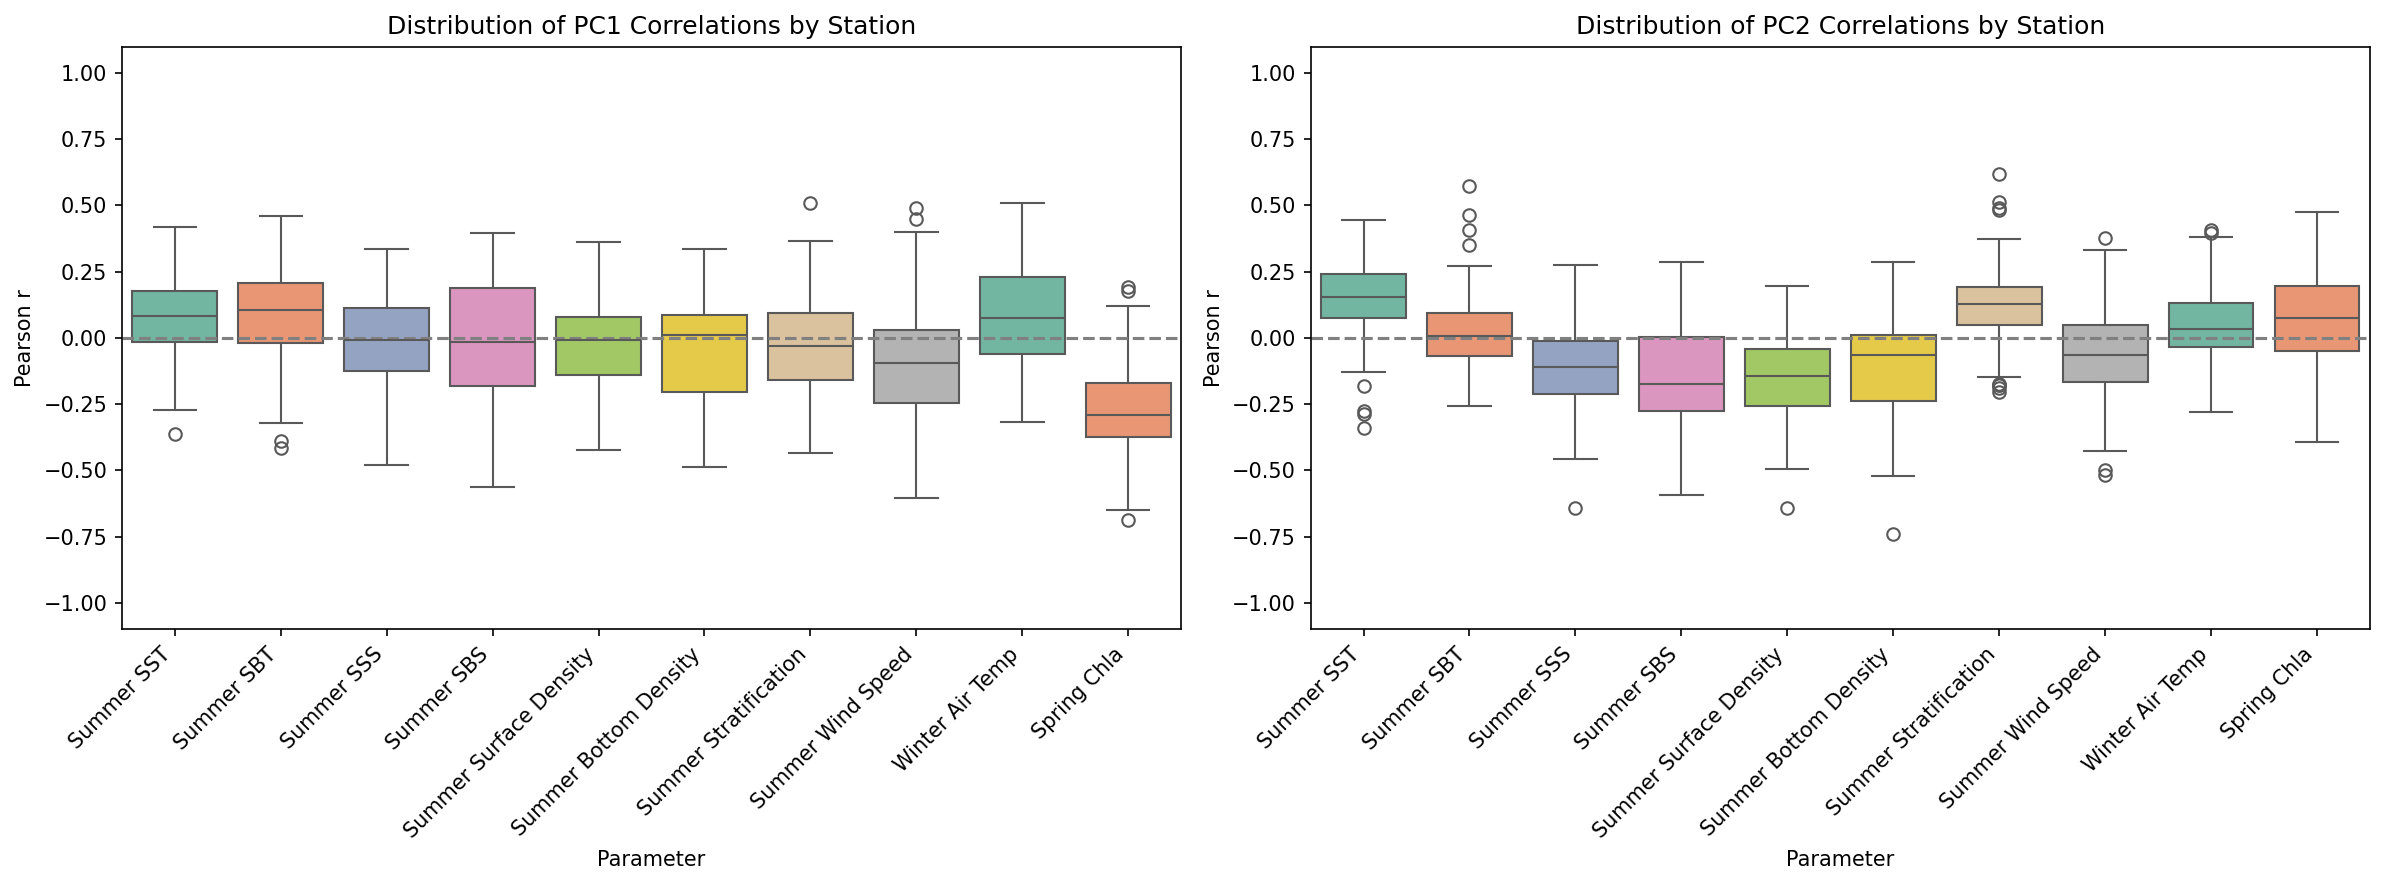

In [4]:
# Visualize Distribution of Correlations across all stations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
    # Filter columns to only those representing Pearson correlation (excluding _pval and _n)
    r_cols = [c for c in corr_df.columns if not c.endswith('_pval') and not c.endswith('_n')]
    
    # Melt dataframe for Seaborn boxplot
    melted = corr_df[r_cols].melt(var_name='Parameter', value_name='Pearson_r')
    
    # Clean parameter names for display
    melted['Parameter'] = melted['Parameter'].str.replace('_', ' ')
    
    sns.boxplot(data=melted, x='Parameter', y='Pearson_r', ax=ax, palette='Set2')
    ax.axhline(0, color='gray', linestyle='--')
    ax.set_title(f'Distribution of {pc_name} Correlations by Station')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.set_ylabel('Pearson r')
    ax.set_ylim(-1.1, 1.1)

plt.tight_layout()
plt.show()


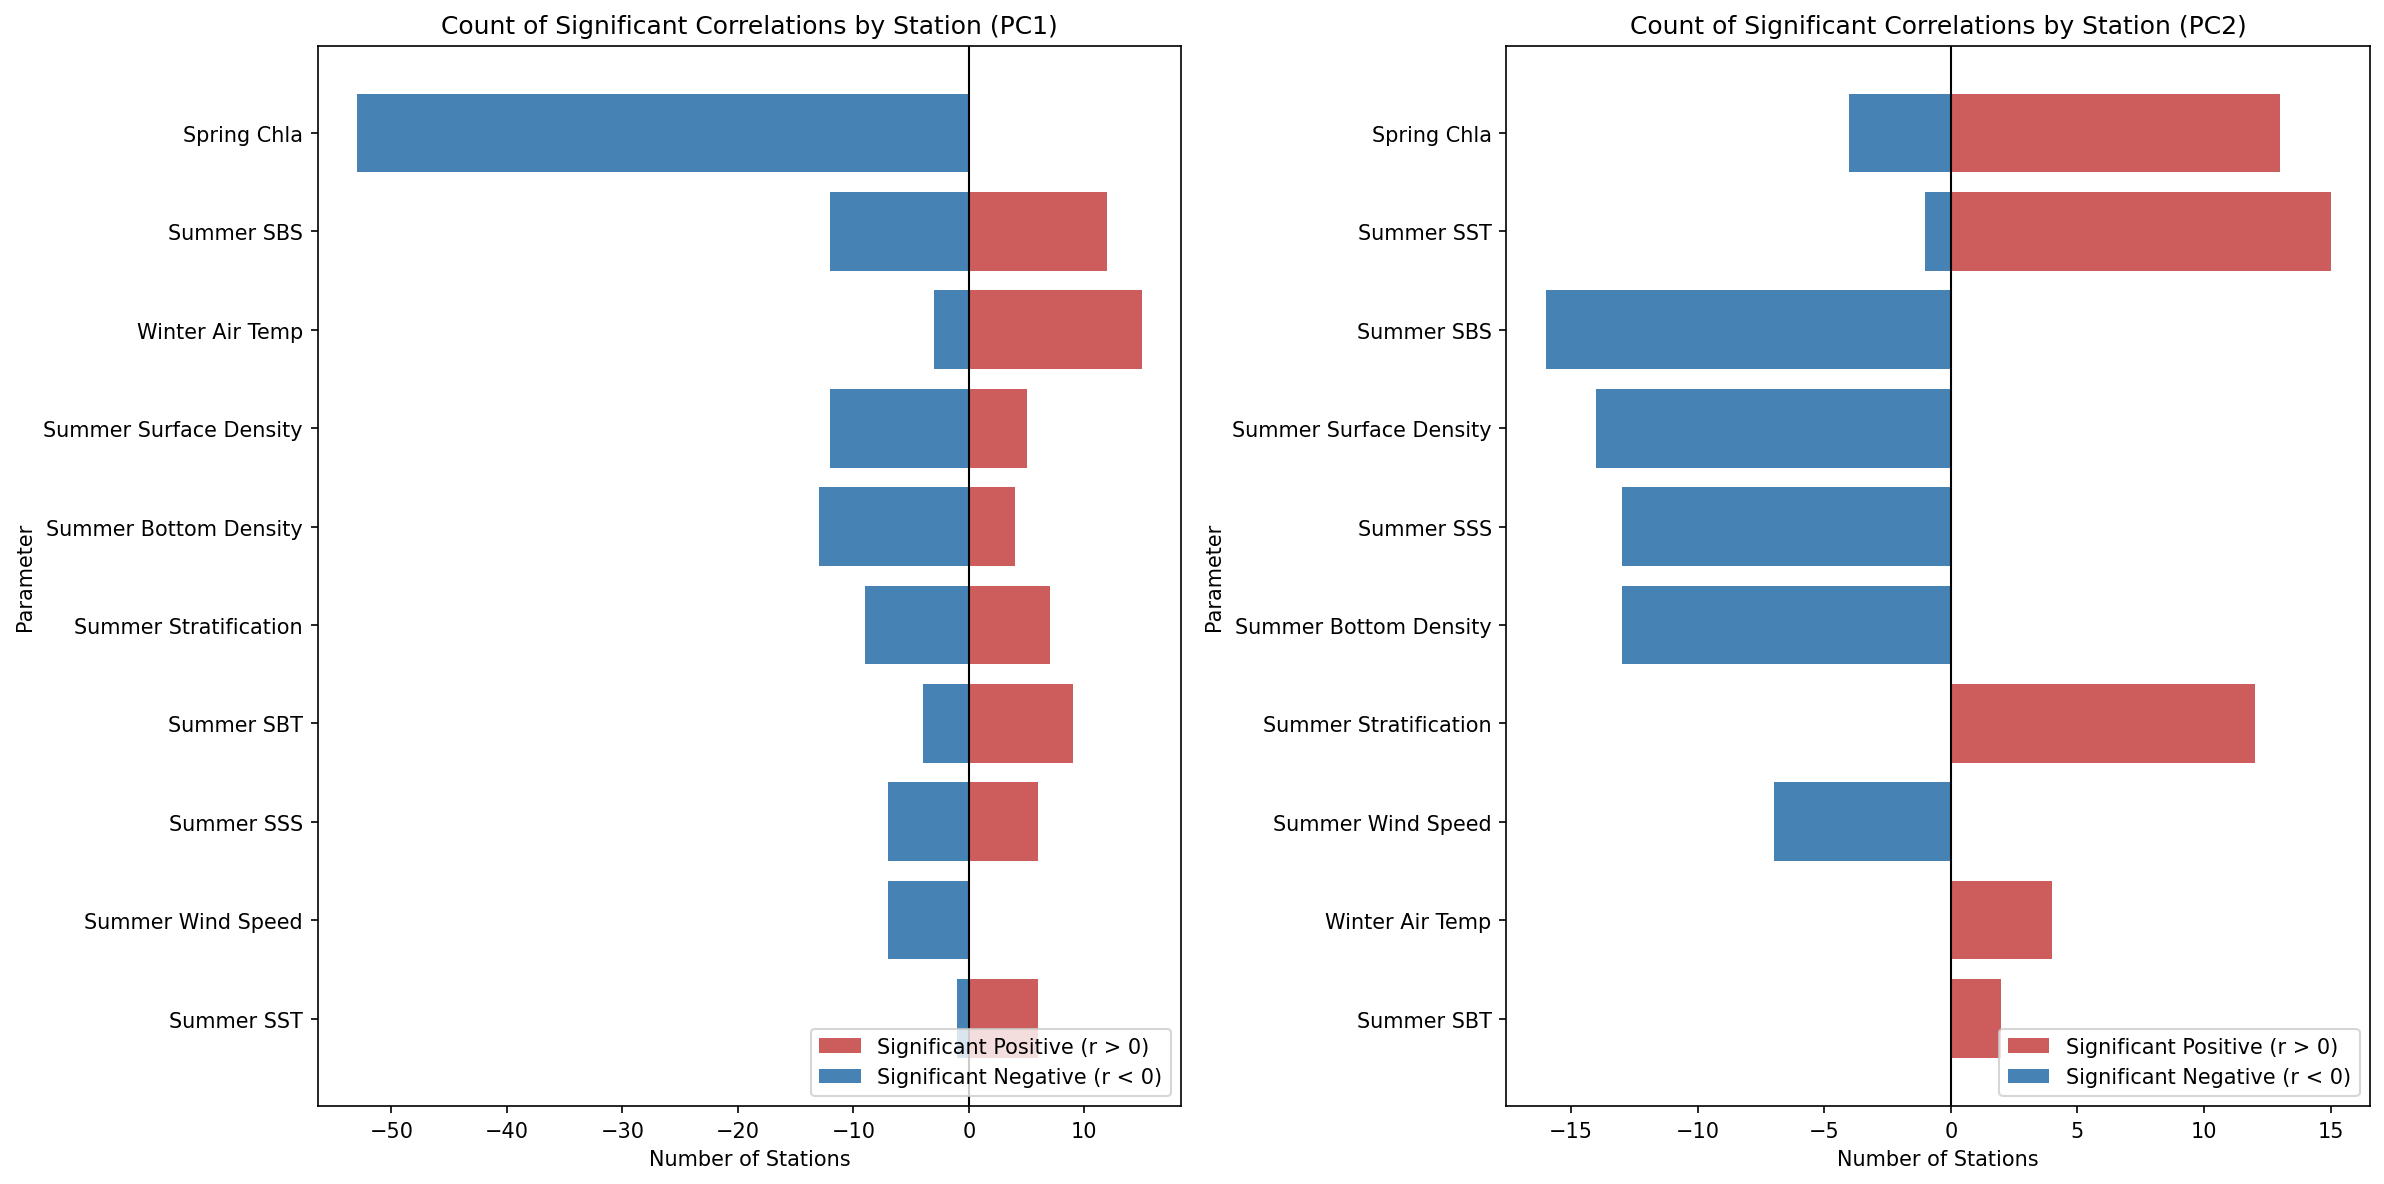

In [5]:
# Create a figure to show the total count of significant positive and negative correlations
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
    # Filter columns to only those representing Pearson correlation (excluding _pval and _n)
    r_cols = [c for c in corr_df.columns if not c.endswith('_pval') and not c.endswith('_n')]
    
    counts = []
    for c in r_cols:
        pval_col = f"{c}_pval"
        # Check if corresponding p-value column exists
        if pval_col in corr_df.columns:
            # Significant positive: r > 0 and p-value < 0.05
            sig_pos = ((corr_df[c] > 0) & (corr_df[pval_col] < 0.05)).sum()
            # Significant negative: r < 0 and p-value < 0.05
            sig_neg = ((corr_df[c] < 0) & (corr_df[pval_col] < 0.05)).sum()
            
            counts.append({
                'Parameter': c.replace('_', ' '),
                'Positive': sig_pos,
                'Negative': -sig_neg, # Converted to negative for diverging bar chart
                'Total_Significant': sig_pos + sig_neg
            })
            
    count_df = pd.DataFrame(counts)
    
    # Rank them based on the total number of significant correlations (ascending for barh)
    count_df = count_df.sort_values(by='Total_Significant', ascending=True)
    
    # Create a diverging horizontal bar chart
    ax.barh(count_df['Parameter'], count_df['Positive'], color='indianred', label='Significant Positive (r > 0)')
    ax.barh(count_df['Parameter'], count_df['Negative'], color='steelblue', label='Significant Negative (r < 0)')
    ax.axvline(0, color='black', linewidth=1)
    
    # Formatting
    ax.set_title(f'Count of Significant Correlations by Station ({pc_name})')
    ax.set_xlabel('Number of Stations')
    ax.set_ylabel('Parameter')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()


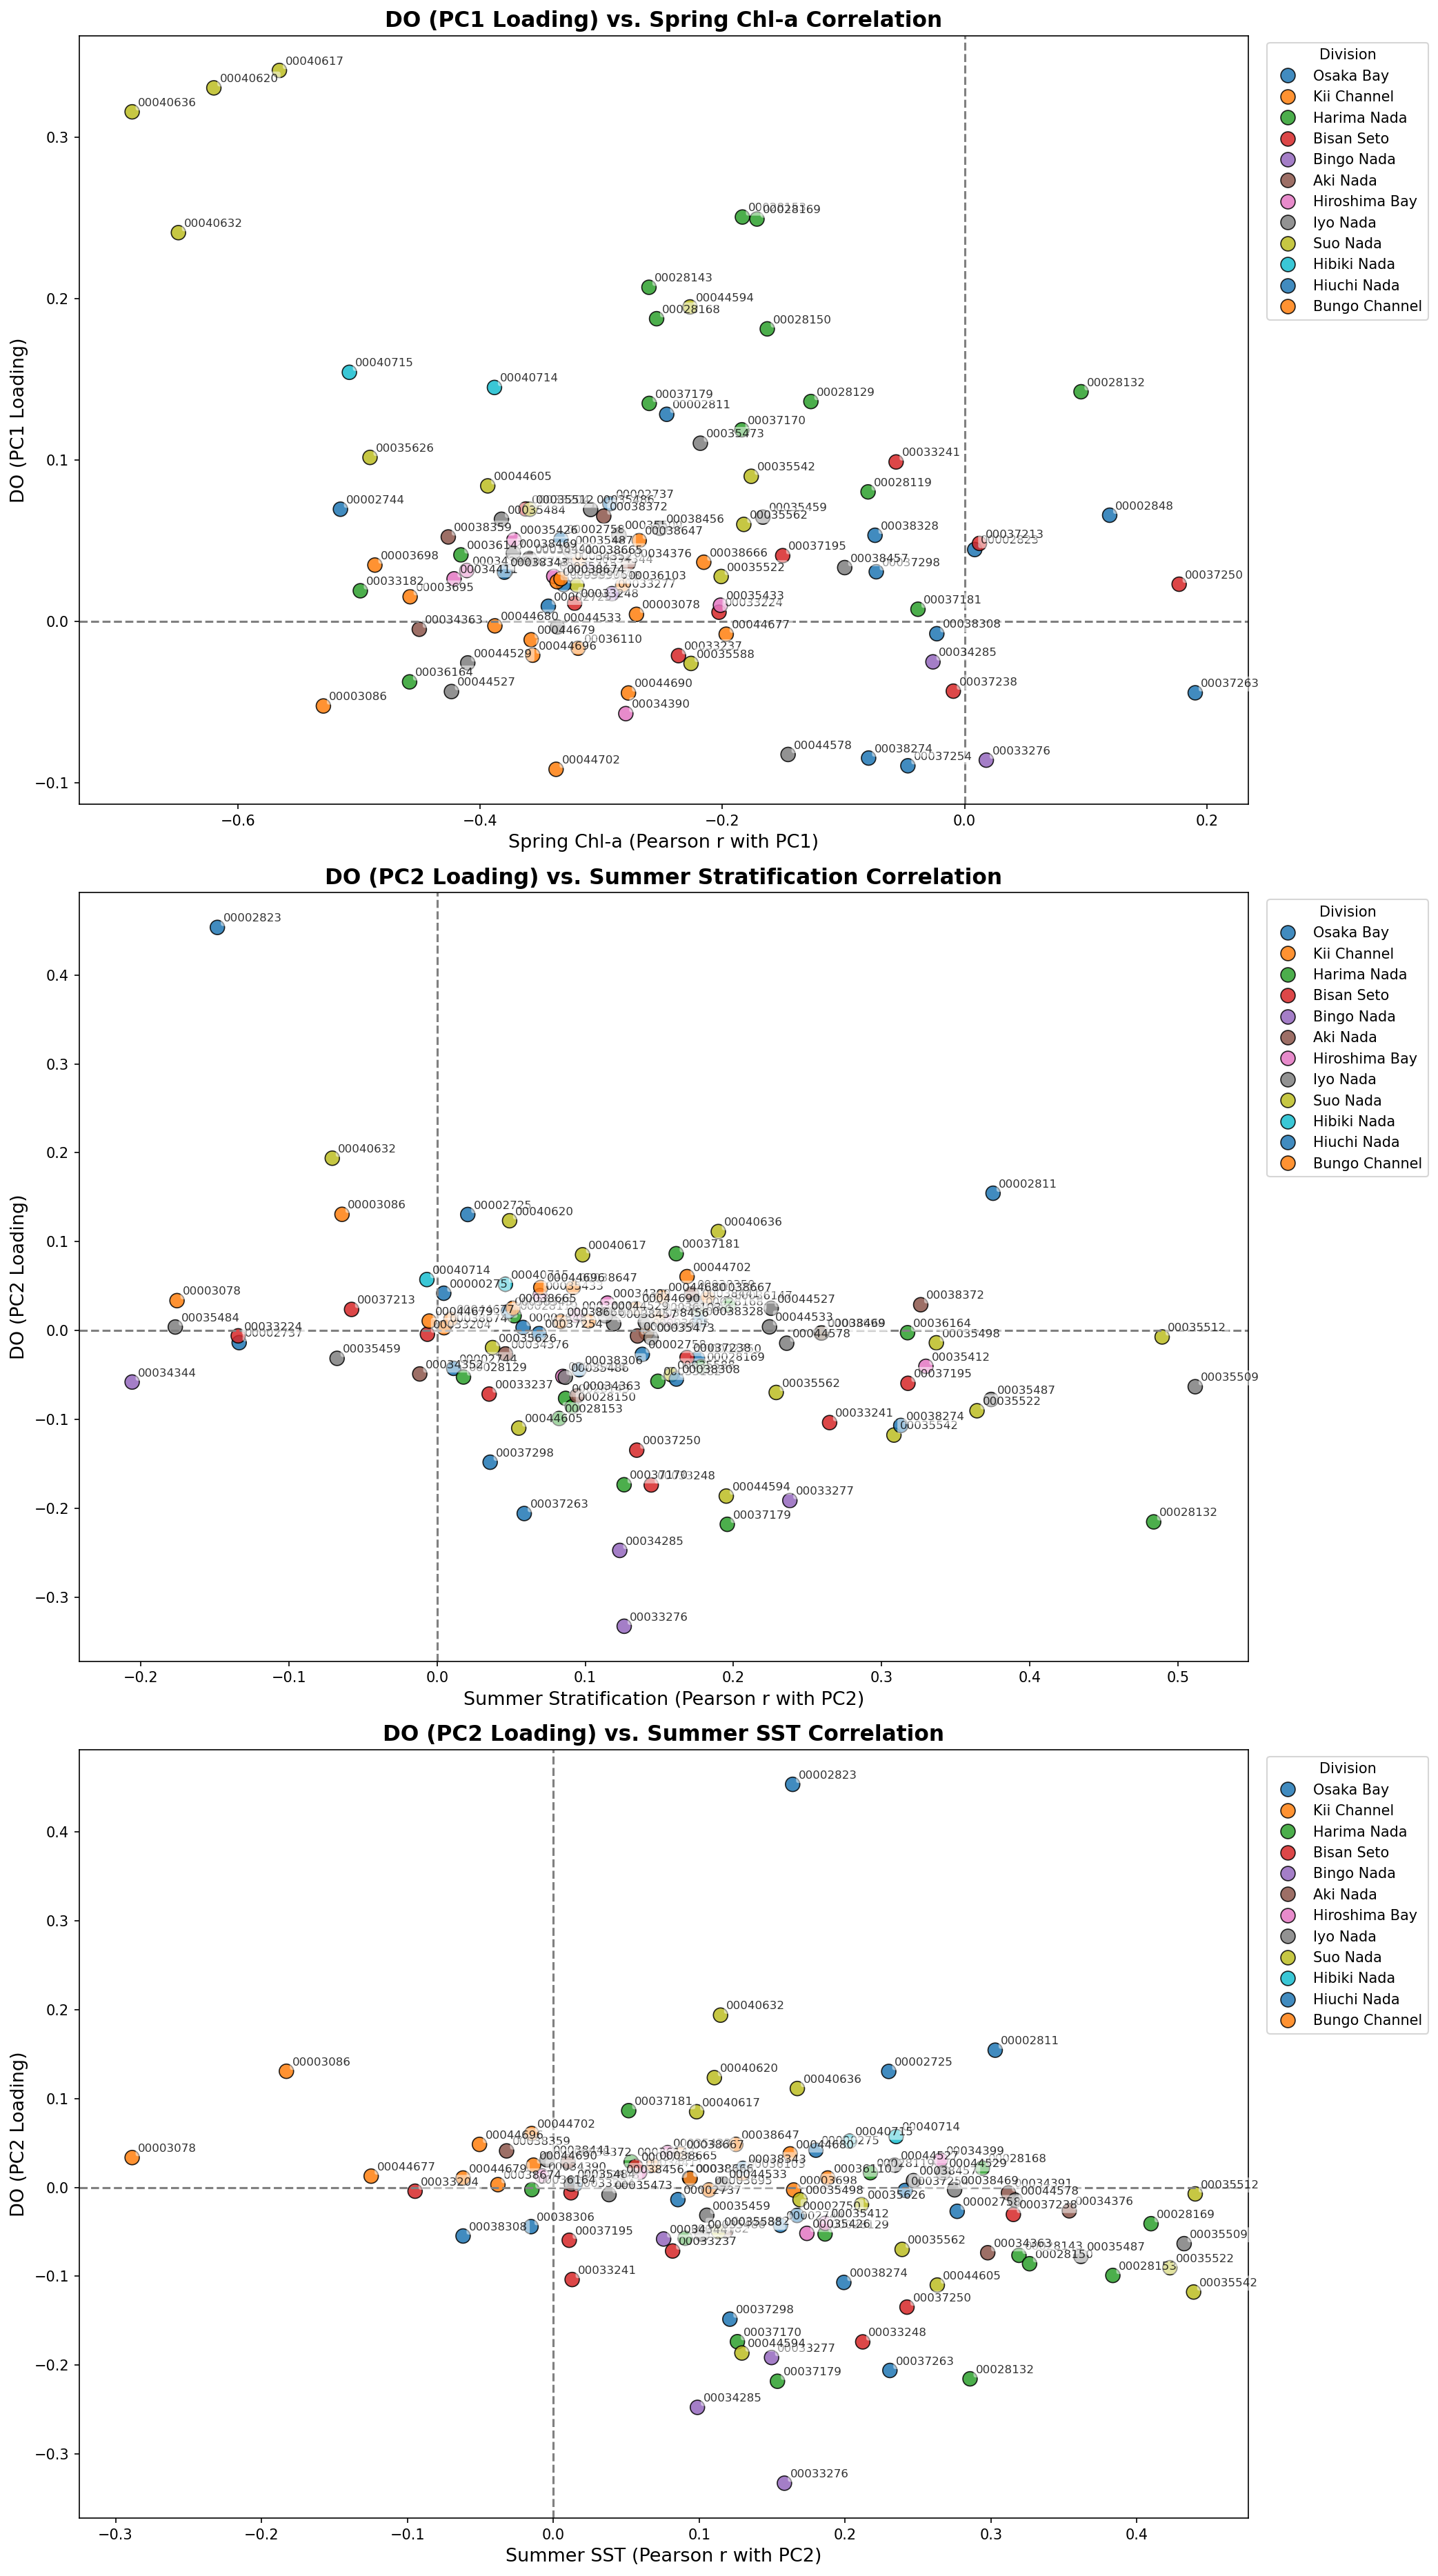

In [7]:
# 3. Create a combined DataFrame for plotting
plot_df = pd.DataFrame(index=corr_df_pc1.index)

# Pipeline correlation cols don't have '_Corr' appended during processing
plot_df['Spring_Chla_Corr'] = corr_df_pc1['Spring_Chla']
plot_df['Summer_Stratification_Corr'] = corr_df_pc2['Summer_Stratification']
plot_df['Summer_SST_Corr'] = corr_df_pc2['Summer_SST']

# Join the DO loadings and divisions
plot_df = plot_df.join(pca_loadings[['PC1_Loading', 'PC2_Loading']])
plot_df = plot_df.join(divisions['division'])

# 4. Generate the 3 scatterplots
fig, axes = plt.subplots(3, 1, figsize=(14, 25))

plots_config = [
    {
        'x': 'Spring_Chla_Corr', 
        'y': 'PC1_Loading', 
        'title': 'DO (PC1 Loading) vs. Spring Chl-a Correlation', 
        'xlabel': 'Spring Chl-a (Pearson r with PC1)', 
        'ylabel': 'DO (PC1 Loading)'
    },
    {
        'x': 'Summer_Stratification_Corr', 
        'y': 'PC2_Loading', 
        'title': 'DO (PC2 Loading) vs. Summer Stratification Correlation', 
        'xlabel': 'Summer Stratification (Pearson r with PC2)', 
        'ylabel': 'DO (PC2 Loading)'
    },
    {
        'x': 'Summer_SST_Corr', 
        'y': 'PC2_Loading', 
        'title': 'DO (PC2 Loading) vs. Summer SST Correlation', 
        'xlabel': 'Summer SST (Pearson r with PC2)', 
        'ylabel': 'DO (PC2 Loading)'
    }
]

# Get unique divisions to create a stable high-contrast color palette
unique_divisions = plot_df['division'].dropna().unique()
palette = sns.color_palette("tab10", n_colors=len(unique_divisions))

for ax, config in zip(axes, plots_config):
    sns.scatterplot(
        data=plot_df, x=config['x'], y=config['y'], hue='division', 
        palette=palette, edgecolor='k', s=100, alpha=0.85, ax=ax
    )
    
    # Reference lines
    ax.axhline(0, color='gray', linestyle='--', zorder=1)
    ax.axvline(0, color='gray', linestyle='--', zorder=1)
    
    # Annotate points
    for idx, row in plot_df.dropna(subset=[config['x'], config['y'], 'division']).iterrows():
        ax.annotate(idx, (row[config['x']], row[config['y']]),
                    xytext=(4, 4), textcoords='offset points',
                    fontsize=8, alpha=0.8,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.5, ec="none"))
                    
    ax.set_title(config['title'], fontsize=15, fontweight='bold')
    ax.set_xlabel(config['xlabel'], fontsize=13)
    ax.set_ylabel(config['ylabel'], fontsize=13)
    ax.legend(title='Division', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()


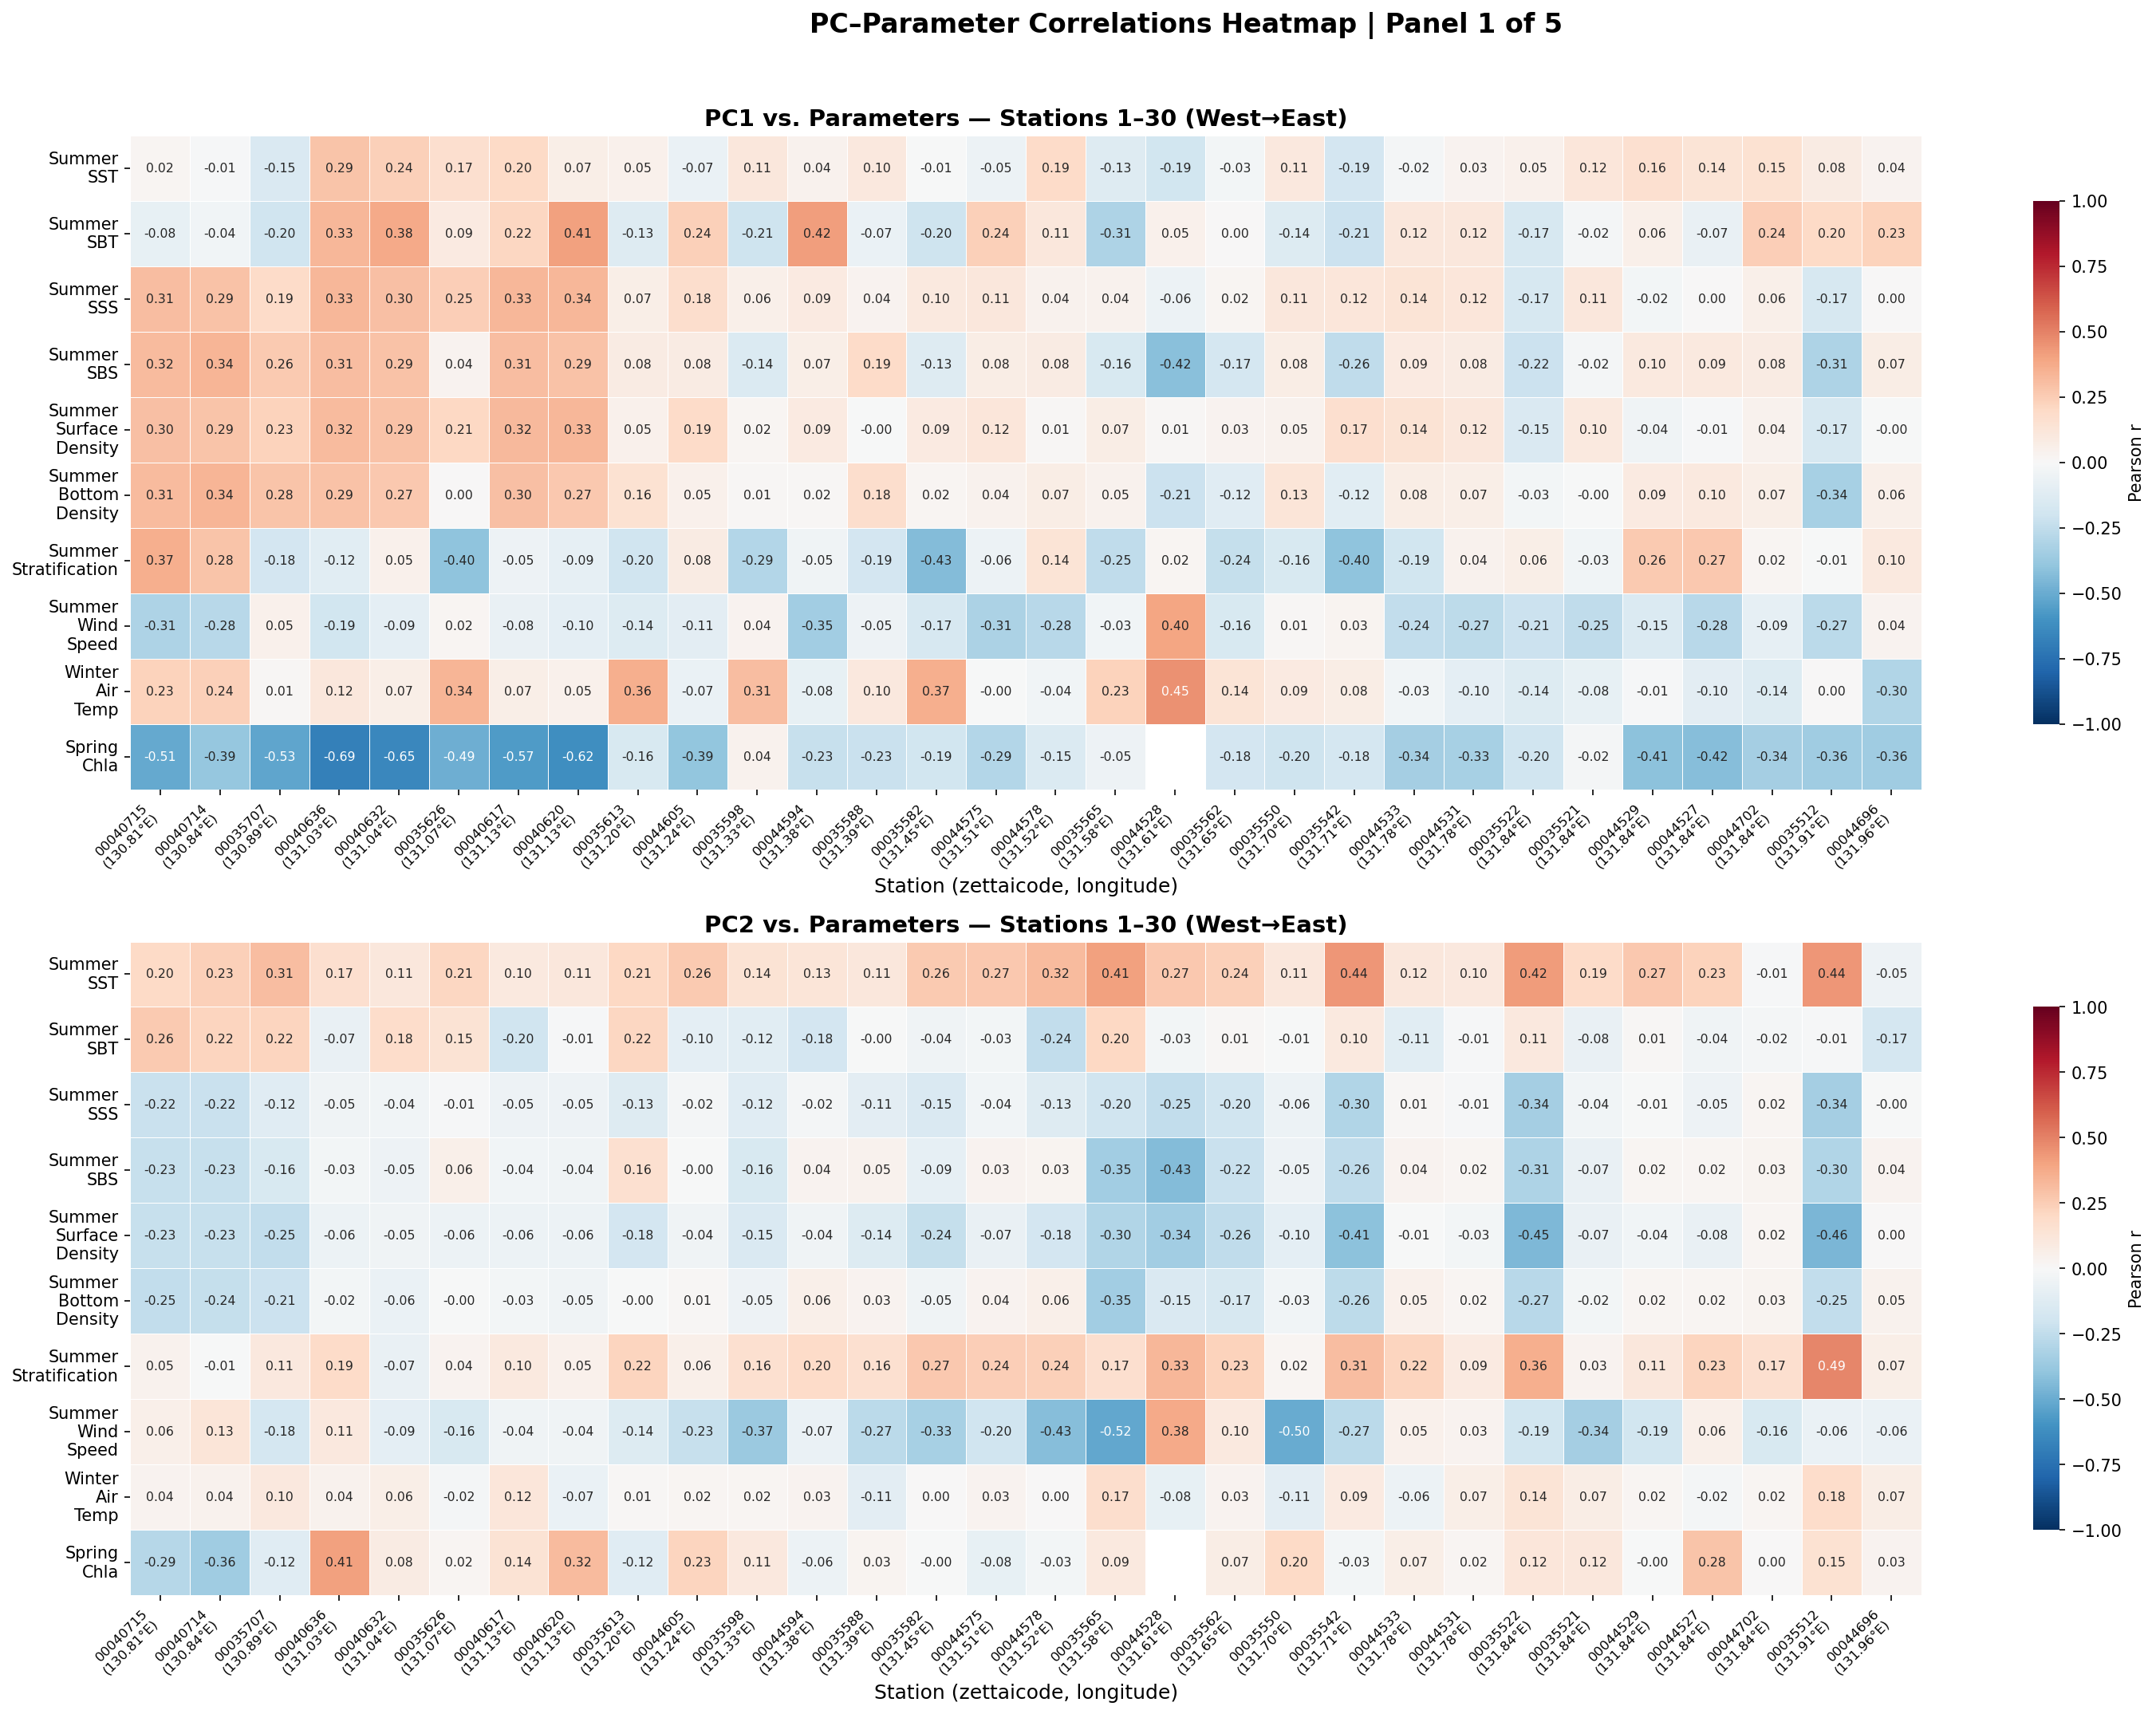

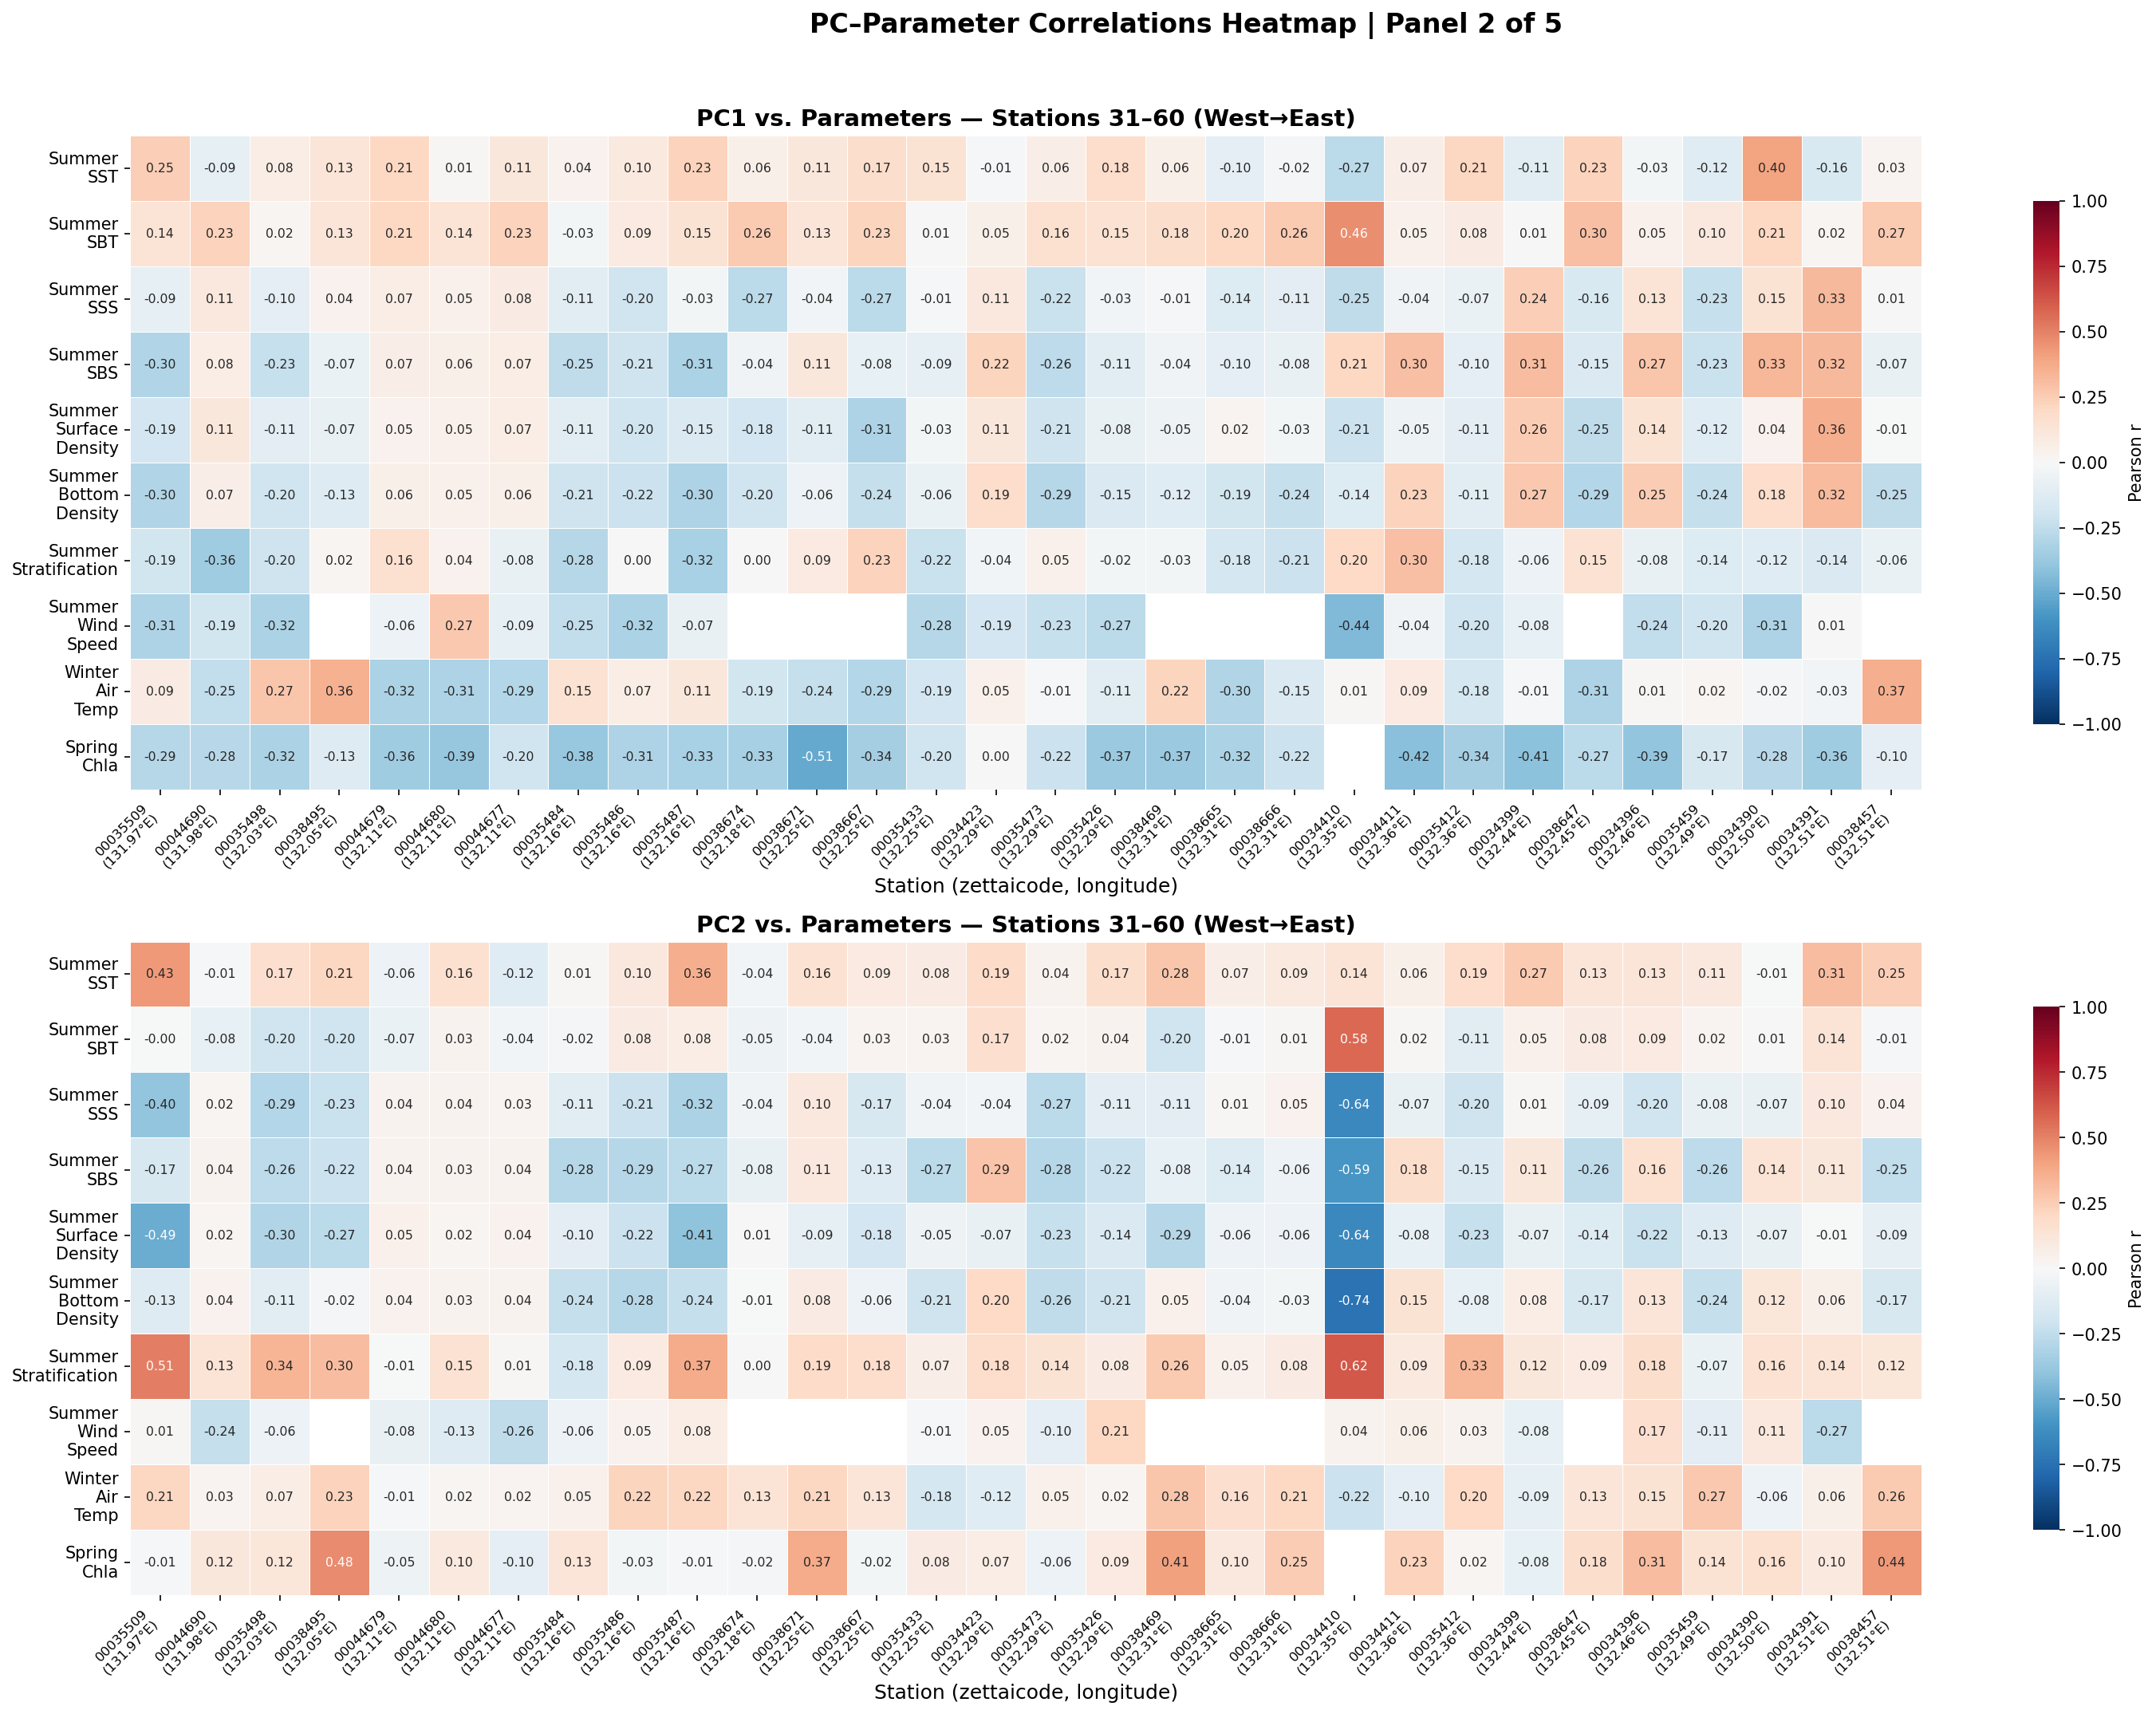

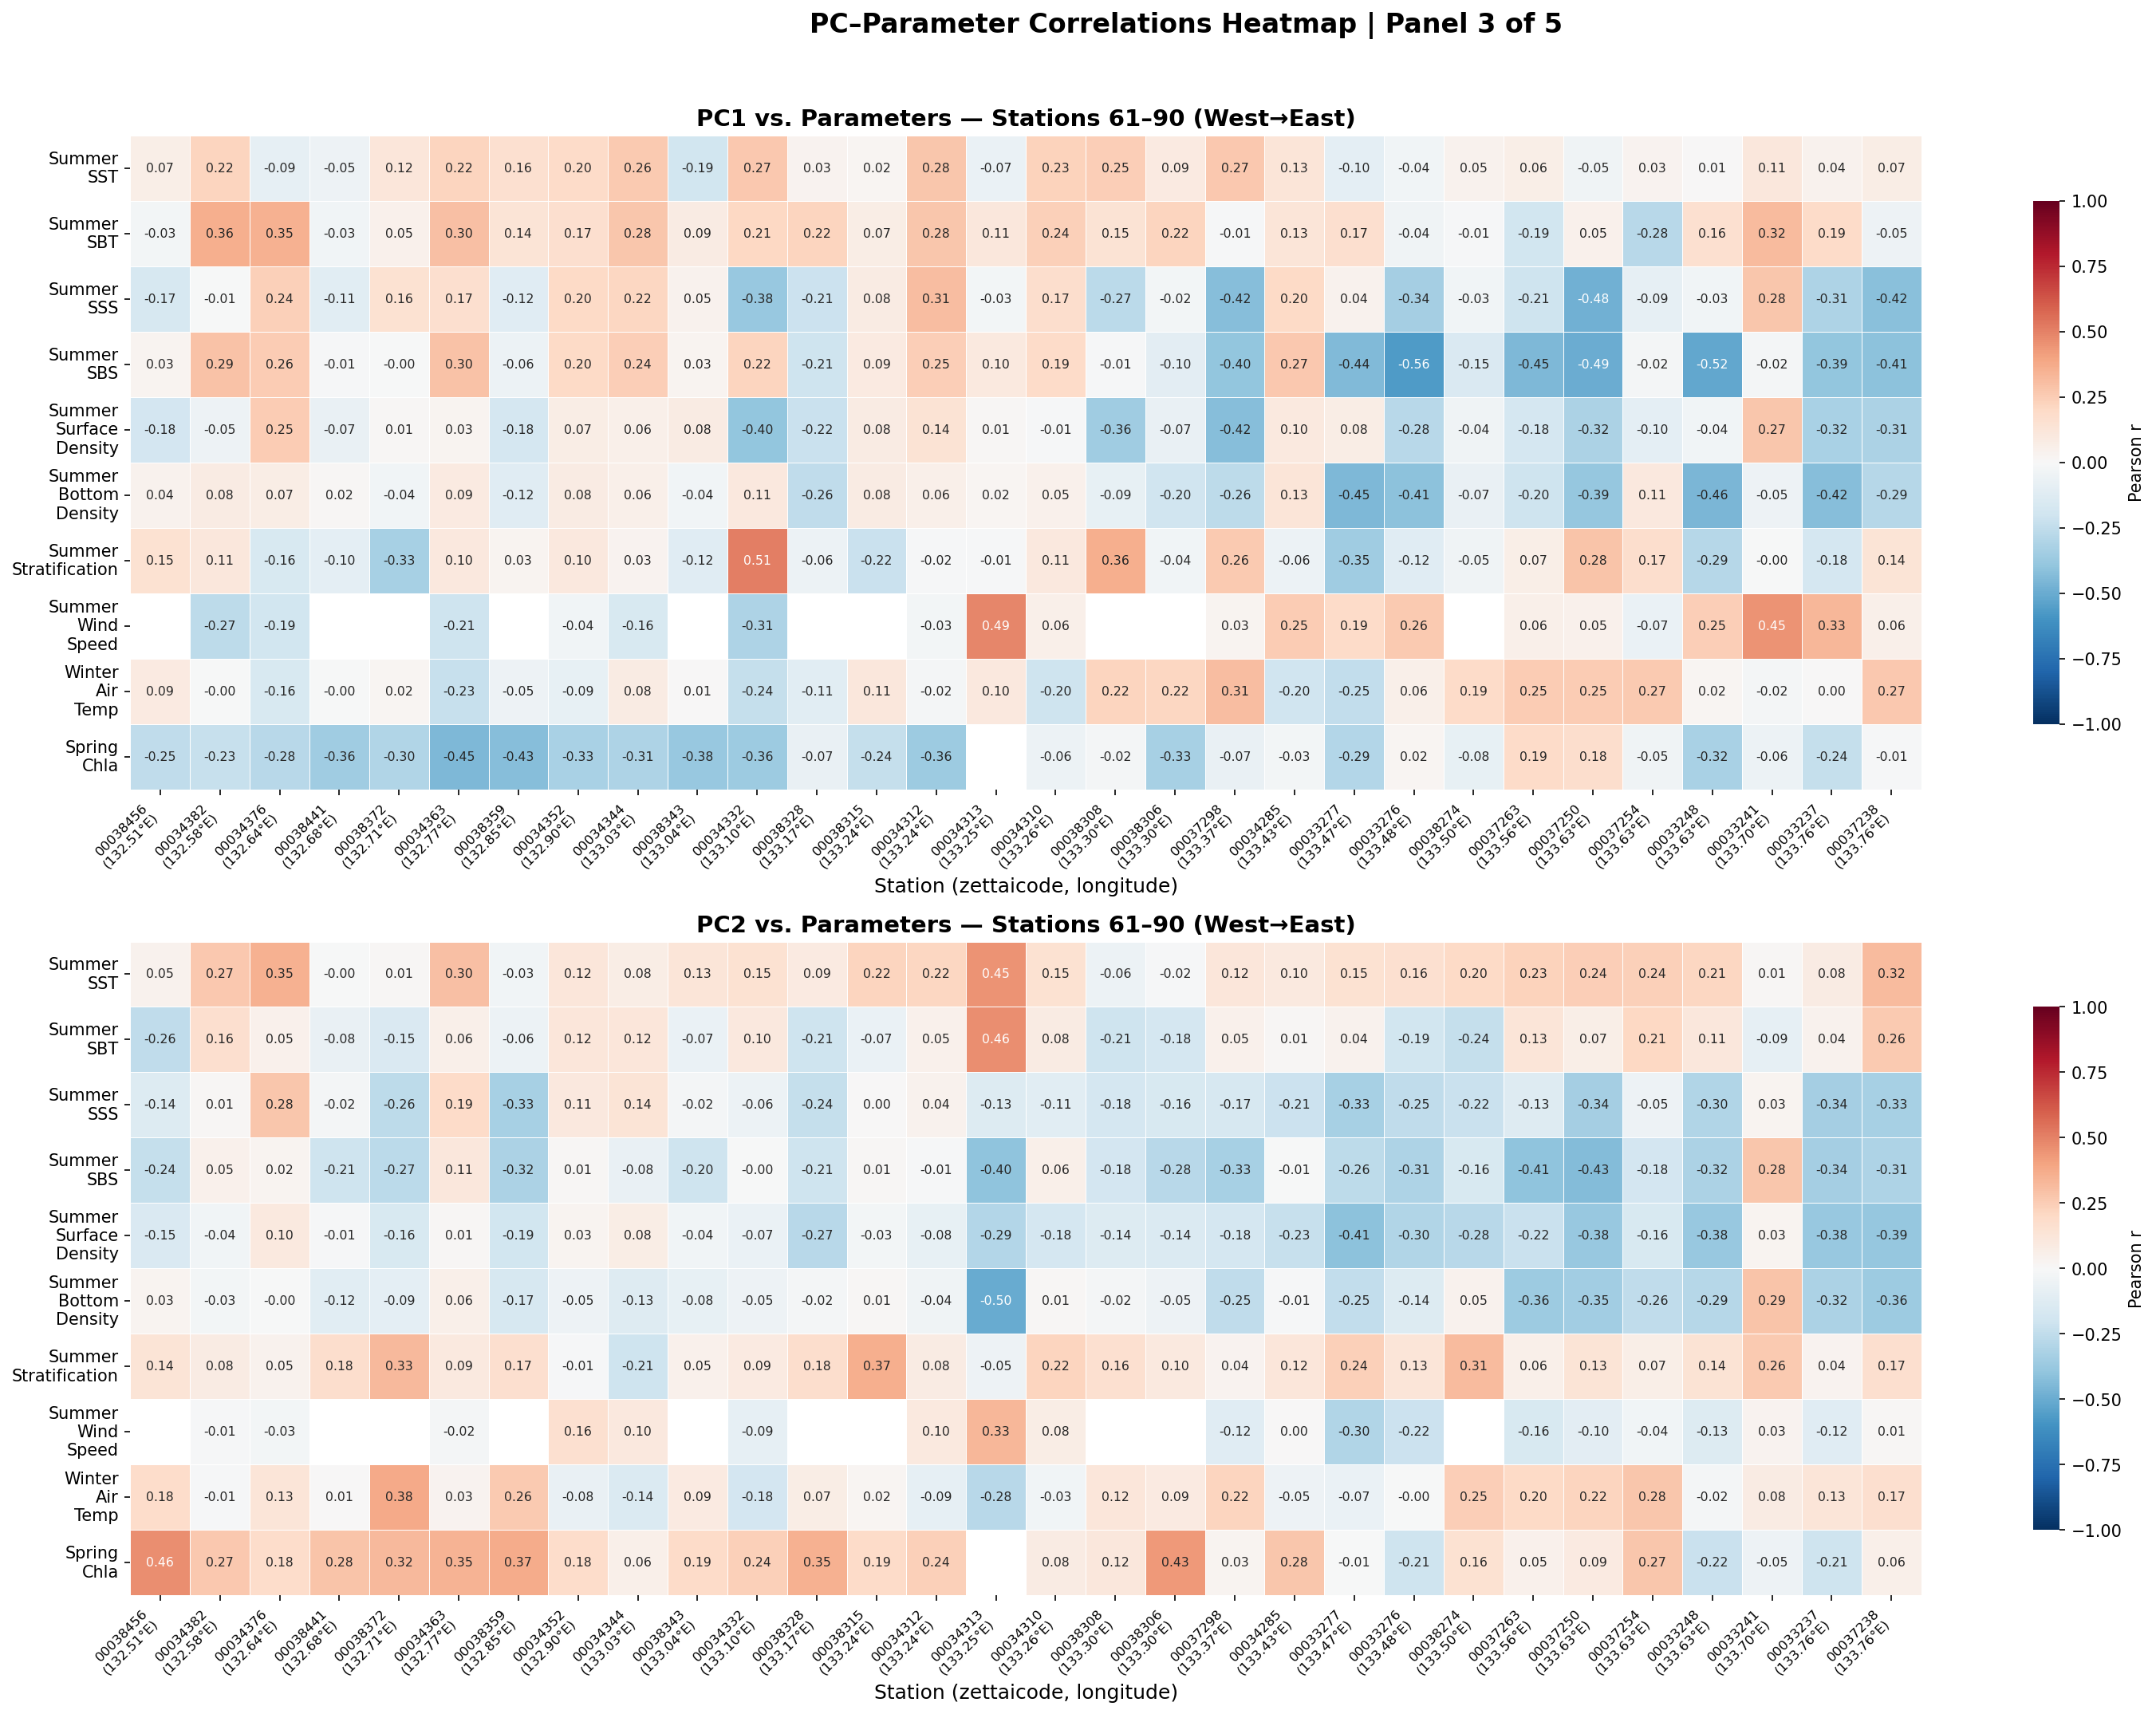

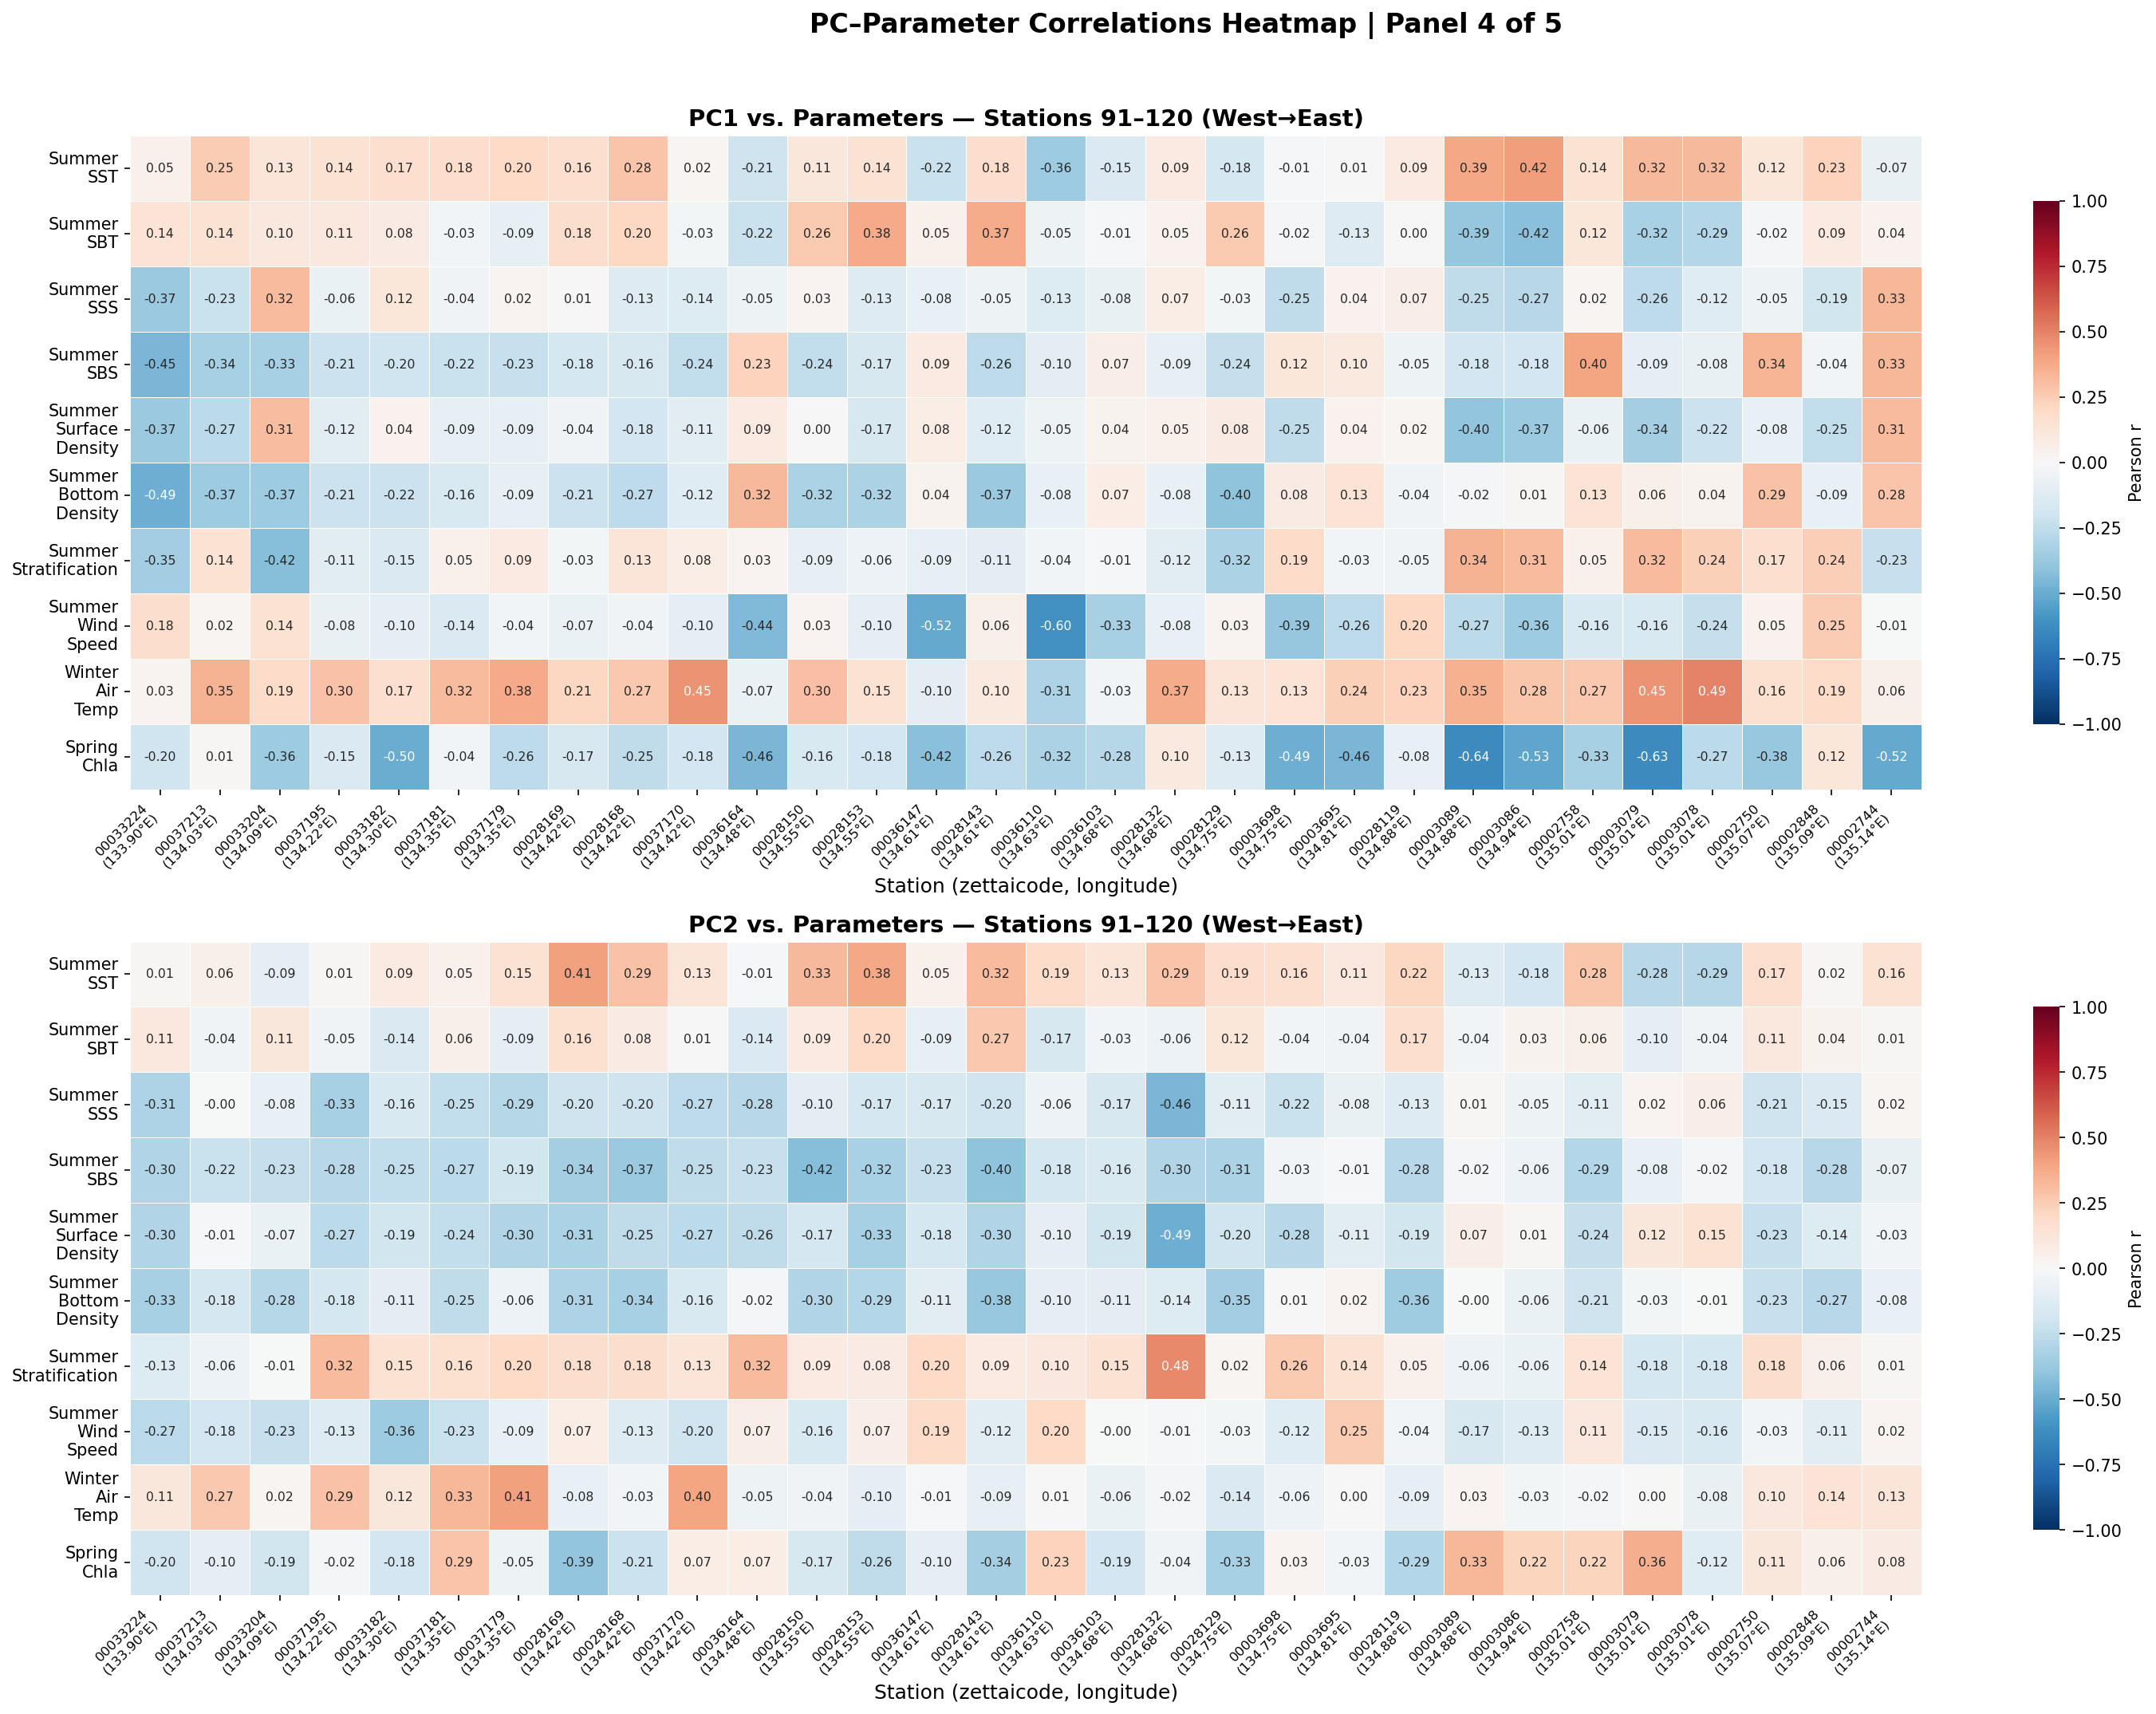

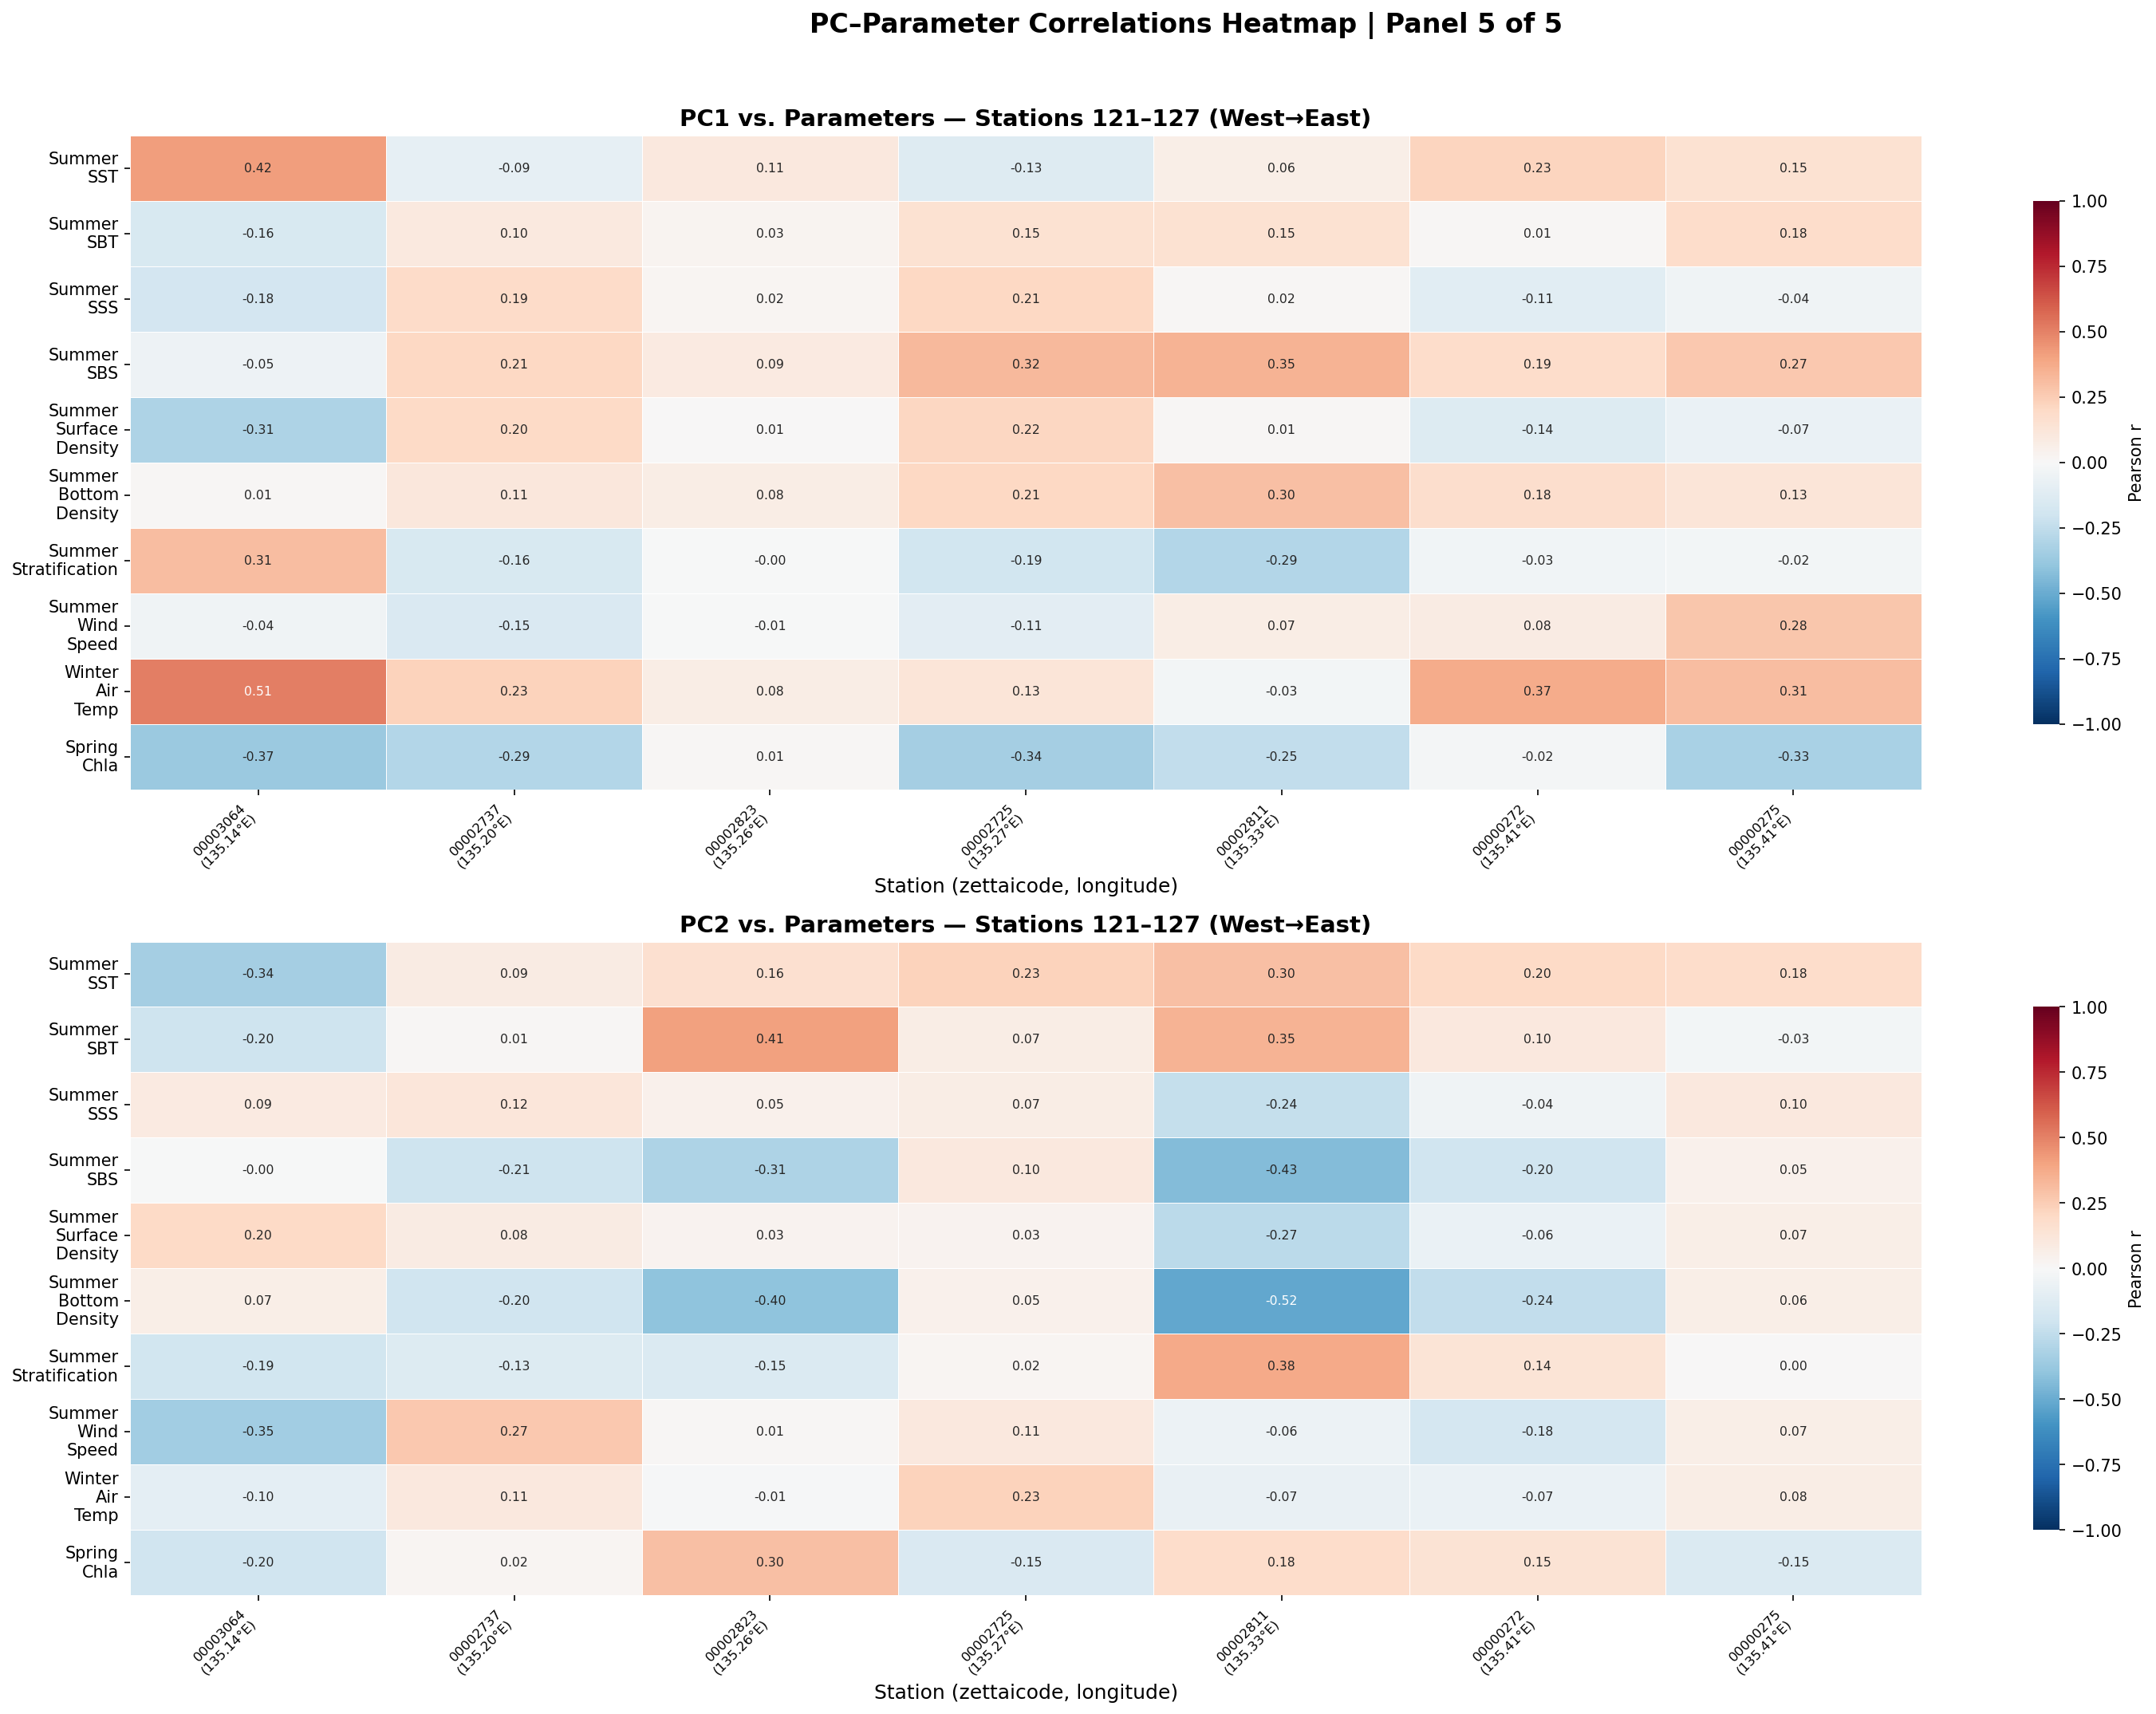

In [8]:
# --- Heatmap: PC1 and PC2 Correlations (Stations on X-axis, Parameters on Y-axis) ---

# Get station coordinates for sorting (west to east = ascending longitude)
stations = merged_df[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode').set_index('zettaicode')

# Only keep stations that appear in either corr_df
all_station_idx = corr_df_pc1.index.union(corr_df_pc2.index)

# Look up longitude for each station and sort ascending (west to east)
station_lon = stations.loc[stations.index.intersection(all_station_idx), 'longitude']
sorted_stations = station_lon.sort_values(ascending=True).index.tolist()

# Parameters (excluding p-value and n-count columns)
r_cols = [c for c in corr_df_pc1.columns if not c.endswith('_pval') and not c.endswith('_n')]

# Chunk into groups of 30 for readable heatmaps
CHUNK_SIZE = 30
chunks = [sorted_stations[i:i + CHUNK_SIZE] for i in range(0, len(sorted_stations), CHUNK_SIZE)]

param_names = [n.replace('_', '\n') for n in r_cols]

for panel_idx, chunk in enumerate(chunks):
    fig, axes = plt.subplots(2, 1, figsize=(20, 14)) # Stack PC1 and PC2 vertically

    for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
        # Select only stations in this chunk that exist in the corr_df
        present = [s for s in chunk if s in corr_df.index]
        
        # TRANSPOSE (.T): stations as columns (x-axis), parameters as index (y-axis)
        plot_data = corr_df.loc[present, r_cols].T

        sns.heatmap(
            plot_data,
            ax=ax,
            cmap='RdBu_r',
            center=0,
            vmin=-1, vmax=1,
            linewidths=0.3,
            annot=True,               # Add text inside grid cells
            fmt=".2f",                # Format correlation floats
            annot_kws={"size": 7.5},  # Font size for cell annotations
            cbar_kws={'label': 'Pearson r', 'shrink': 0.8},
            yticklabels=param_names,  # Cleaned parameter names on Y
        )

        # Annotate each station label with its longitude for reference on X-axis
        xtick_labels = []
        for stn in present:
            lon_val = station_lon.get(stn, float('nan'))
            xtick_labels.append(f"{stn}\n({lon_val:.2f}°E)")
            
        ax.set_xticklabels(xtick_labels, fontsize=8, rotation=45, ha='right')
        ax.set_yticklabels(ax.get_yticklabels(), fontsize=10, rotation=0)

        start_rank = panel_idx * CHUNK_SIZE + 1
        end_rank   = start_rank + len(present) - 1
        ax.set_title(
            f'{pc_name} vs. Parameters — Stations {start_rank}–{end_rank} (West→East)',
            fontsize=14, fontweight='bold'
        )
        ax.set_xlabel('Station (zettaicode, longitude)', fontsize=12)

    plt.suptitle(
        f'PC–Parameter Correlations Heatmap | Panel {panel_idx + 1} of {len(chunks)} ',
        fontsize=16, fontweight='bold', y=1.02
    )
    plt.tight_layout()

    save_path = ProjectPaths.FIGURES_DIR / f'pc_param_heatmap_west_to_east_panel{panel_idx + 1}.png'
    plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()
